# FieldShift: which crops fit this county, in a dry, typical, or wet season?

NASA Space Apps Challenge 2026, "Adapting Farms with NASA Data". North Dakota prototype.

**What this notebook does**

1. Pulls county yields for 8 crops from USDA NASS (2000 to 2025).
2. Pulls daily weather, satellite rain and soil wetness for every county from NASA POWER (2000 to 2025).
3. Trains one model per crop and tests it the honest way: train on past years, test on a later year it never saw.
4. Turns the model into a "what if" tool: the change in yield in a dry or wet season.
5. Writes `docs/data.js`, the file the web app reads.

**What it is not:** a forecast. The model needs the whole season's weather, which nobody has at planting time. That is why the app asks "what kind of season?" and never claims to know.

Every download is cached in `data/raw`, so a second run is fast and works offline.

In [1]:
import sys, json, time, warnings
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

# In Colab: paste the GitHub repo URL here to reuse the cached data files.
# Leave it empty to download everything fresh (about 5 minutes).
REPO_URL = ""

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and REPO_URL and not Path("data/raw").exists():
    import subprocess, os
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "fieldshift_repo"], check=True)
    os.chdir("fieldshift_repo")

ROOT = Path(".")
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
DOCS = ROOT / "docs"
for folder in [RAW, PROCESSED, DOCS]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_START = 2000                 # first year downloaded (2000 only feeds the winter before the 2001 season)
FIRST_YEAR, LAST_YEAR = 2001, 2025
YEARS = list(range(FIRST_YEAR, LAST_YEAR + 1))
print("Working in:", ROOT.resolve())

Working in: /home/claude/fieldshift


## 1. Crops

One entry per crop: the exact USDA "Data Item" for yield and for price, the unit, and what equipment the crop usually needs. The equipment tags drive the filters in the app. They are general rules of thumb, not data.

In [2]:
CROPS = {
    "spring_wheat": dict(
        label="Spring wheat", unit="bu/acre",
        item="WHEAT, SPRING, (EXCL DURUM) - YIELD, MEASURED IN BU / ACRE",
        price_item="WHEAT, SPRING, (EXCL DURUM) - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["drill"]),
    "durum": dict(
        label="Durum wheat", unit="bu/acre",
        item="WHEAT, SPRING, DURUM - YIELD, MEASURED IN BU / ACRE",
        price_item="WHEAT, SPRING, DURUM - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["drill"]),
    "barley": dict(
        label="Barley", unit="bu/acre",
        item="BARLEY - YIELD, MEASURED IN BU / ACRE",
        price_item="BARLEY - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["drill"]),
    "canola": dict(
        label="Canola", unit="lb/acre",
        item="CANOLA - YIELD, MEASURED IN LB / ACRE",
        price_item="CANOLA - PRICE RECEIVED, MEASURED IN $ / CWT", price_div=100,
        needs=["drill"]),
    "dry_peas": dict(
        label="Dry peas", unit="lb/acre",
        item="PEAS, DRY EDIBLE - YIELD, MEASURED IN LB / ACRE",
        price_item="PEAS, DRY EDIBLE - PRICE RECEIVED, MEASURED IN $ / CWT", price_div=100,
        needs=["drill"]),
    "soybeans": dict(
        label="Soybeans", unit="bu/acre",
        item="SOYBEANS - YIELD, MEASURED IN BU / ACRE",
        price_item="SOYBEANS - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["drill_or_planter"]),
    "corn": dict(
        label="Corn (grain)", unit="bu/acre",
        item="CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",
        price_item="CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["planter", "corn_head"]),
    "sunflower": dict(
        label="Sunflower (oil)", unit="lb/acre",
        item="SUNFLOWER, OIL TYPE - YIELD, MEASURED IN LB / ACRE",
        price_item="SUNFLOWER, OIL TYPE - PRICE RECEIVED, MEASURED IN $ / CWT", price_div=100,
        needs=["planter"]),
}

## 2. USDA NASS yields and prices

This uses the same route as the Quick Stats website's "Spreadsheet" button, so no API key is needed. If USDA ever blocks it, run the query by hand at quickstats.nass.usda.gov, click Spreadsheet, and save the file under the cache name used below.

In [3]:
NASS = "https://quickstats.nass.usda.gov"
HEADERS = {"User-Agent": "Mozilla/5.0 (FieldShift student project)"}

def nass_table(filters, years, cache_file):
    """Download one Quick Stats query as a table. Cached on disk."""
    if cache_file.exists():
        return pd.read_csv(cache_file, dtype=str)
    form = list(filters.items()) + [("year", str(y)) for y in years]
    uuid = requests.post(f"{NASS}/uuid/encode", data=form, headers=HEADERS, timeout=120)
    uuid.raise_for_status()
    uuid = uuid.text.strip().strip('"')
    csv = requests.get(f"{NASS}/data/spreadsheet/{uuid}.csv", headers=HEADERS, timeout=300)
    csv.raise_for_status()
    cache_file.write_bytes(csv.content)
    return pd.read_csv(cache_file, dtype=str)

yield_raw = nass_table(
    {"source_desc": "SURVEY", "sector_desc": "CROPS", "group_desc": "FIELD CROPS",
     "statisticcat_desc": "YIELD", "agg_level_desc": "COUNTY", "state_name": "NORTH DAKOTA"},
    range(DATA_START, LAST_YEAR + 1), RAW / "nass_nd_field_crop_yields_2000_2025.csv")

price_raw = nass_table(
    {"source_desc": "SURVEY", "sector_desc": "CROPS", "group_desc": "FIELD CROPS",
     "statisticcat_desc": "PRICE RECEIVED", "agg_level_desc": "STATE",
     "state_name": "NORTH DAKOTA", "freq_desc": "ANNUAL"},
    range(2021, LAST_YEAR + 1), RAW / "nass_nd_prices_2021_2025.csv")

print("Yield rows:", len(yield_raw), "| Price rows:", len(price_raw))

Yield rows: 16775 | Price rows: 146


In [4]:
def to_number(series):
    return pd.to_numeric(series.astype(str).str.replace(",", "", regex=False), errors="coerce")

item_to_crop = {c["item"]: key for key, c in CROPS.items()}

y = yield_raw[yield_raw["Data Item"].isin(item_to_crop)].copy()
# Rows without a county code are "OTHER COUNTIES" lumps. They are not one place, so drop them.
y = y[y["County ANSI"].notna() & (y["Period"] == "YEAR")].copy()

yields = pd.DataFrame({
    "year": y["Year"].astype(int),
    "county_fips": y["State ANSI"].str.zfill(2) + y["County ANSI"].str.zfill(3),
    "county": y["County"].str.strip().str.title(),
    "crop": y["Data Item"].map(item_to_crop),
    "yield": to_number(y["Value"]),
}).dropna(subset=["yield"]).reset_index(drop=True)

assert not yields.duplicated(["crop", "county_fips", "year"]).any(), "duplicate county-year rows"

coverage = yields.pivot_table(index="crop", columns="year", values="yield", aggfunc="size").fillna(0).astype(int)
print("Counties reporting, by crop and year:")
display(coverage.loc[:, 2010:])

Counties reporting, by crop and year:


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
crop,,,,,,,,,,,,,,,,
barley,41,27,31,10,34,18,36,33,21,18,27,24,25,20,0,16
canola,35,31,25,15,13,14,26,28,15,13,27,25,31,26,25,19
corn,45,45,47,32,33,36,43,34,24,21,45,45,44,48,42,31
dry_peas,26,8,9,5,4,12,27,13,10,4,15,12,8,9,6,6
durum,18,10,8,2,6,5,15,15,9,5,18,18,12,14,0,11
soybeans,35,33,32,27,33,32,36,39,35,34,48,46,45,42,40,35
spring_wheat,51,45,39,19,42,33,36,38,40,30,50,47,48,42,0,36
sunflower,36,28,23,9,15,14,14,16,11,0,33,27,25,17,10,10


Two things to notice in that table:

* USDA only publishes a county when enough farms report, so the number of counties changes every year.
* Small grains (wheat, durum, barley) have no county numbers for 2024. Row crops do.

In [5]:
p = price_raw[(price_raw["Period"] == "MARKETING YEAR")].copy()
p["price"] = to_number(p["Value"])
p["year"] = p["Year"].astype(int)

prices = {}
for key, c in CROPS.items():
    rows = p[p["Data Item"] == c["price_item"]].dropna(subset=["price"]).sort_values("year")
    assert len(rows), f"no price found for {key}"
    last = rows.iloc[-1]
    prices[key] = dict(price=round(float(last["price"]) / c["price_div"], 4), year=int(last["year"]))

price_table = pd.DataFrame(prices).T
price_table["per"] = [CROPS[k]["unit"].split("/")[0] for k in price_table.index]
print("North Dakota average price received, latest marketing year (USDA NASS):")
display(price_table)

North Dakota average price received, latest marketing year (USDA NASS):


,price,year,per
spring_wheat,5.330,2025.0,bu
durum,6.100,2025.0,bu
barley,4.760,2025.0,bu
canola,0.212,2025.0,lb
dry_peas,0.112,2025.0,lb
soybeans,9.790,2025.0,bu
corn,3.800,2025.0,bu
sunflower,0.237,2025.0,lb


## 3. County locations

In [6]:
gaz_file = RAW / "2024_gaz_counties_38.txt"
if not gaz_file.exists():
    url = "https://www2.census.gov/geo/docs/maps-data/data/gazetteer/2024_Gazetteer/2024_gaz_counties_38.txt"
    gaz_file.write_bytes(requests.get(url, headers=HEADERS, timeout=120).content)

counties = pd.read_csv(gaz_file, sep="\t", dtype={"GEOID": str})
counties.columns = counties.columns.str.strip()
counties = counties.rename(columns={"GEOID": "county_fips", "NAME": "name",
                                    "INTPTLAT": "latitude", "INTPTLONG": "longitude"})
counties["name"] = counties["name"].str.replace(" County", "", regex=False).str.strip()
counties = counties[["county_fips", "name", "latitude", "longitude"]]
print("Counties:", len(counties))

Counties: 53


## 4. NASA POWER: weather, satellite rain, soil wetness

One request per county center, daily values for 2000 to 2025. The daily values are rolled up to one row per county, year and month:

| Column | Meaning | Source inside POWER |
|---|---|---|
| `t_mean`, `tmax_mean`, `tmin_mean` | temperature | MERRA-2 |
| `rain`, `wet_days` | rain total, days with 1 mm or more | MERRA-2, corrected |
| `rain_imerg` | rain total from satellites | GPM IMERG |
| `heat30`, `heat34`, `frost_days` | days at or above 30 C, 34 C, at or below 0 C | MERRA-2 |
| `gdd0`, `gdd10` | growing degree days, base 0 C (small grains) and base 10 C capped at 30 C (corn) | MERRA-2 |
| `vpd` | how dry the air is (vapor pressure deficit, kPa) | MERRA-2 |
| `solar`, `rh`, `wind` | sunlight, humidity, wind | CERES, MERRA-2 |
| `gwetroot`, `gwettop` | soil wetness in the root zone and at the surface (0 dry to 1 soaked) | MERRA-2 land model |

Note on soil moisture: this is NASA's modeled soil wetness, which covers every year. SMAP satellite soil moisture only starts in 2015, too short to train on here.

In [7]:
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
POWER_PARAMS = ["T2M", "T2M_MAX", "T2M_MIN", "PRECTOTCORR", "IMERG_PRECTOT",
                "ALLSKY_SFC_SW_DWN", "RH2M", "WS10M", "GWETROOT", "GWETTOP"]

def monthly_from_daily(d):
    """Roll daily POWER values up to months. -999 is NASA's missing value marker."""
    d = d.replace(-999, np.nan).copy()
    t, tx, tn = d["T2M"], d["T2M_MAX"], d["T2M_MIN"]
    ok = t.notna() & tx.notna() & tn.notna()
    d["n_days"] = ok
    d["wet"] = d["PRECTOTCORR"] >= 1
    d["h30"], d["h34"], d["frost"] = (tx >= 30) & ok, (tx >= 34) & ok, (tn <= 0) & ok
    d["g0"] = ((tx + tn) / 2).clip(lower=0).where(ok)
    d["g10"] = ((tx.clip(upper=30) + tn.clip(lower=10)) / 2 - 10).clip(lower=0).where(ok)
    d["vpd_day"] = (0.6108 * np.exp(17.27 * t / (t + 237.3)) * (1 - d["RH2M"] / 100)).where(ok)
    g = d.groupby([d["DATE"].dt.year.rename("year"), d["DATE"].dt.month.rename("month")])
    return g.agg(
        n_days=("n_days", "sum"), t_mean=("T2M", "mean"), tmax_mean=("T2M_MAX", "mean"), tmin_mean=("T2M_MIN", "mean"),
        rain=("PRECTOTCORR", "sum"), n_rain=("PRECTOTCORR", "count"), wet_days=("wet", "sum"),
        rain_imerg=("IMERG_PRECTOT", "sum"), n_imerg=("IMERG_PRECTOT", "count"),
        heat30=("h30", "sum"), heat34=("h34", "sum"), frost_days=("frost", "sum"),
        gdd0=("g0", "sum"), gdd10=("g10", "sum"), vpd=("vpd_day", "mean"),
        solar=("ALLSKY_SFC_SW_DWN", "mean"), rh=("RH2M", "mean"), wind=("WS10M", "mean"),
        gwetroot=("GWETROOT", "mean"), gwettop=("GWETTOP", "mean")).reset_index()

monthly_file = RAW / "power_monthly_2000_2025.csv"
if monthly_file.exists():
    monthly = pd.read_csv(monthly_file, dtype={"county_fips": str})
else:
    parts = []
    for c in counties.itertuples(index=False):
        response = requests.get(POWER_URL, timeout=300, params={
            "parameters": ",".join(POWER_PARAMS), "community": "AG",
            "latitude": round(c.latitude, 4), "longitude": round(c.longitude, 4),
            "start": f"{DATA_START}0101", "end": f"{LAST_YEAR}1231",
            "format": "JSON", "time-standard": "UTC"})
        response.raise_for_status()
        daily = pd.DataFrame(response.json()["properties"]["parameter"])
        daily.index = pd.to_datetime(daily.index, format="%Y%m%d")
        daily.index.name = "DATE"
        part = monthly_from_daily(daily.reset_index())
        part.insert(0, "county_fips", c.county_fips)
        parts.append(part)
        print("Downloaded", c.name)
        time.sleep(0.5)
    monthly = pd.concat(parts, ignore_index=True)
    monthly.to_csv(monthly_file, index=False)

print("County-months:", len(monthly), "| counties:", monthly["county_fips"].nunique())
assert monthly["n_days"].min() >= 28, "a month is missing days"

County-months: 16536 | counties: 53


## 5. Season features

Each crop is decided at a different time of year: wheat by June and early July, corn by July and August, soybeans by August rain. So the model gets month by month values, plus what the season started with.

* **Month by month:** rain April to September, temperature May to August, hot days and air dryness June to August, growing degree days, frost in May and September.
* **What the season started with:** soil wetness in April and May, and rain from the previous October to March.
* **Satellite rain:** IMERG totals May to August, as a second opinion on the rain.

In [8]:
def season_features(monthly):
    w = monthly.pivot_table(index=["county_fips", "year"], columns="month")
    col = lambda name, month: w[(name, month)]
    f = pd.DataFrame(index=w.index)

    season = [5, 6, 7, 8, 9]
    days = sum(col("n_days", m) for m in season)
    # Whole-season totals (the 6 weather features from the first notebook, kept for the before/after comparison)
    f["avg_temp_c"] = sum(col("t_mean", m) * col("n_days", m) for m in season) / days
    f["total_rain_mm"] = sum(col("rain", m) for m in season)
    f["heat_days_30c"] = sum(col("heat30", m) for m in season)
    f["avg_solar"] = sum(col("solar", m) * col("n_days", m) for m in season) / days
    f["avg_humidity"] = sum(col("rh", m) * col("n_days", m) for m in season) / days
    f["avg_wind"] = sum(col("wind", m) * col("n_days", m) for m in season) / days

    # Month by month
    for m in [4, 5, 6, 7, 8, 9]:
        f[f"rain_{m}"] = col("rain", m)
    for m in [5, 6, 7, 8]:
        f[f"temp_{m}"] = col("t_mean", m)
    for m in [6, 7, 8]:
        f[f"heat30_{m}"] = col("heat30", m)
        f[f"vpd_{m}"] = col("vpd", m)
    f["gdd0_apr_jul"] = sum(col("gdd0", m) for m in [4, 5, 6, 7])
    f["gdd10_may_sep"] = sum(col("gdd10", m) for m in season)
    f["solar_jun_aug"] = (col("solar", 6) + col("solar", 7) + col("solar", 8)) / 3
    f["frost_may"] = col("frost_days", 5)
    f["frost_sep"] = col("frost_days", 9)

    # What the season started with, and satellite rain
    f["soilwet_root_apr"] = col("gwetroot", 4)
    f["soilwet_root_may"] = col("gwetroot", 5)
    f["soilwet_top_apr"] = col("gwettop", 4)
    for m in [5, 6, 7, 8]:
        f[f"imerg_{m}"] = col("rain_imerg", m)
    f = f.reset_index()

    winter = monthly[monthly["month"].isin([10, 11, 12, 1, 2, 3])].copy()
    winter["year"] = np.where(winter["month"] >= 10, winter["year"] + 1, winter["year"])   # Oct to Dec count toward next season
    winter = winter.groupby(["county_fips", "year"]).agg(preseason_rain=("rain", "sum"), months=("rain", "size")).reset_index()
    winter = winter[winter["months"] == 6].drop(columns="months")
    return f.merge(winter, on=["county_fips", "year"], how="inner")

OLD_FEATURES = ["latitude", "longitude", "avg_temp_c", "total_rain_mm", "heat_days_30c", "avg_solar", "avg_humidity", "avg_wind"]
FEATURES = (["latitude", "longitude"]
            + [f"rain_{m}" for m in [4, 5, 6, 7, 8, 9]] + [f"temp_{m}" for m in [5, 6, 7, 8]]
            + [f"heat30_{m}" for m in [6, 7, 8]] + [f"vpd_{m}" for m in [6, 7, 8]]
            + ["gdd0_apr_jul", "gdd10_may_sep", "solar_jun_aug", "frost_may", "frost_sep"]
            + ["soilwet_root_apr", "soilwet_root_may", "soilwet_top_apr", "preseason_rain"]
            + [f"imerg_{m}" for m in [5, 6, 7, 8]])

county_weather = counties.merge(season_features(monthly), on="county_fips")
county_weather = county_weather[county_weather["year"].between(FIRST_YEAR, LAST_YEAR)].reset_index(drop=True)
assert not county_weather[FEATURES].isna().any().any()

print("County-seasons:", len(county_weather), "| features:", len(FEATURES))
display(county_weather.groupby("year")[["total_rain_mm", "heat_days_30c", "soilwet_root_apr"]].mean().round(2).loc[2010:].T)

County-seasons: 1325 | features: 31


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
total_rain_mm,455.24,426.00,221.22,411.63,393.80,347.85,368.33,269.97,323.58,462.97,270.95,255.37,307.29,341.43,360.48,369.15
heat_days_30c,24.85,20.77,51.58,26.13,12.81,37.04,32.47,40.08,40.66,22.13,33.62,62.79,39.45,38.60,37.38,33.47
soilwet_root_apr,0.48,0.51,0.45,0.44,0.49,0.45,0.45,0.46,0.44,0.46,0.50,0.41,0.48,0.45,0.45,0.44


## 6. Training table

In [9]:
data = yields[yields["year"].between(FIRST_YEAR, LAST_YEAR)].merge(
    county_weather.drop(columns=["name"]), on=["county_fips", "year"], how="inner", validate="many_to_one")
data.to_csv(PROCESSED / "fieldshift_training_multicrop.csv", index=False)

display(data.groupby("crop").agg(rows=("yield", "size"), counties=("county_fips", "nunique"),
                                 years=("year", "nunique"), mean_yield=("yield", "mean")).round(1).loc[list(CROPS)])

,rows,counties,years,mean_yield
crop,,,,
spring_wheat,1069,53,24,41.0
durum,483,49,24,33.2
barley,820,53,24,59.0
canola,701,50,25,1502.9
dry_peas,355,47,21,2089.9
soybeans,903,51,25,30.8
corn,1003,53,25,107.4
sunflower,708,53,24,1475.8


## 7. Models and honest testing

Four ways to predict a county's yield:

* **County average.** The county's own average since 2010. This is the bar to beat.
* **Recent median.** The county's middle value over the previous 6 years. No weather, no model.
* **Old forest.** The setup from the first notebook: a random forest on location plus 6 whole-season weather totals, trained on 2010 onward.
* **New model.** A random forest on the month by month features above, trained on 2001 onward. It predicts yield *relative to the statewide trend line*, because yields climb over time as seed and practices improve, and a plain forest can never predict above what it has already seen.

**The test:** for each year from 2016 to 2024, train only on earlier years, then predict that year. No number below comes from data the model saw. 2025 is kept out of all of this and used once at the end.

In [10]:
def make_forest():
    return RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1)

def fit_trend(train):
    """Statewide yield trend. Theil-Sen line, so one drought year cannot tilt it."""
    means = train.groupby("year")["yield"].mean()
    x, v = means.index.to_numpy(float), means.to_numpy(float)
    slopes = [(v[j] - v[i]) / (x[j] - x[i]) for i in range(len(x)) for j in range(i + 1, len(x))]
    slope = float(np.median(slopes)) if slopes else 0.0
    intercept = float(np.median(v - slope * x))
    floor = 0.5 * float(np.median(v))
    return lambda years: np.maximum(intercept + slope * np.asarray(years, float), floor)

def fit_new_model(train):
    trend = fit_trend(train)
    forest = make_forest().fit(train[FEATURES], train["yield"] / trend(train["year"]))
    return forest, trend

def predict_all(crop_data, all_yields, test):
    """Predictions for the test rows from all four methods. crop_data holds only years before the test year."""
    out = {}
    since_2010 = crop_data[crop_data["year"] >= 2010]
    county_mean = since_2010.groupby("county_fips")["yield"].mean()
    out["County average"] = test["county_fips"].map(county_mean).fillna(since_2010["yield"].mean()).to_numpy()

    test_year = int(test["year"].iloc[0])
    recent = all_yields[all_yields["year"].between(test_year - 6, test_year - 1)]
    recent_median = recent.groupby("county_fips")["yield"].median()
    out["Recent median"] = test["county_fips"].map(recent_median).fillna(recent["yield"].median()).to_numpy()

    out["Old forest"] = make_forest().fit(since_2010[OLD_FEATURES], since_2010["yield"]).predict(test[OLD_FEATURES])

    forest, trend = fit_new_model(crop_data)
    out["New model"] = forest.predict(test[FEATURES]) * trend(test["year"])
    return out

MODELS = ["County average", "Recent median", "Old forest", "New model"]

def evaluate(test_years, min_train_years=5):
    rows, predictions = [], []
    for crop in CROPS:
        d = data[data["crop"] == crop]
        all_yields = yields[yields["crop"] == crop]
        for test_year in test_years:
            train, test = d[d["year"] < test_year], d[d["year"] == test_year]
            if len(test) < 5 or train[train["year"] >= 2010]["year"].nunique() < min_train_years:
                continue
            preds = predict_all(train, all_yields, test)
            for model, pred in preds.items():
                err = pred - test["yield"].to_numpy()
                rows.append({"crop": crop, "year": test_year, "model": model, "n": len(test),
                             "MAE": np.abs(err).mean(), "bias": err.mean(), "mean_yield": test["yield"].mean(),
                             "predicted_low_in": int((err < 0).sum())})
            predictions.append(test[["crop", "county", "year", "yield"]].assign(predicted=preds["New model"]))
    return pd.DataFrame(rows), pd.concat(predictions, ignore_index=True)

folds, fold_predictions = evaluate(range(2016, 2025))
folds.to_csv(PROCESSED / "fieldshift_forward_validation.csv", index=False)
print("Test folds:", folds.groupby("crop")["year"].nunique().to_dict())

Test folds: {'barley': 8, 'canola': 9, 'corn': 9, 'dry_peas': 8, 'durum': 8, 'soybeans': 9, 'spring_wheat': 8, 'sunflower': 8}


In [11]:
summary = folds.pivot_table(index="crop", columns="model", values="MAE", aggfunc="mean")[MODELS].loc[list(CROPS)]
mean_yield = folds.groupby("crop")["mean_yield"].mean()
summary_pct = summary.div(mean_yield, axis=0) * 100

print("Average error on unseen years, 2016 to 2024 (in each crop's own unit):")
display(summary.round(1))
print("Same thing as a percent of the crop's average yield:")
display(summary_pct.round(1))
print("Average over the 8 crops (%):")
print(summary_pct.mean().round(1).to_string())
print("\nError relative to the county average (below 1.0 is better):")
print(summary.div(summary["County average"], axis=0).mean().round(3).to_string())

Average error on unseen years, 2016 to 2024 (in each crop's own unit):


model,County average,Recent median,Old forest,New model
crop,,,,
spring_wheat,7.0,6.7,6.5,5.8
durum,9.9,11.0,8.2,6.8
barley,10.2,10.0,10.4,9.1
canola,292.3,299.9,241.8,193.7
dry_peas,509.5,534.3,496.6,468.7
soybeans,5.4,5.6,6.0,4.8
corn,19.8,20.8,20.0,16.8
sunflower,350.7,301.1,295.7,253.6


Same thing as a percent of the crop's average yield:


model,County average,Recent median,Old forest,New model
crop,,,,
barley,15.1,14.8,15.4,13.5
canola,16.9,17.4,14.0,11.2
corn,16.3,17.2,16.5,13.9
dry_peas,21.5,22.5,20.9,19.7
durum,24.6,27.2,20.2,17.0
soybeans,16.3,17.2,18.2,14.6
spring_wheat,15.0,14.4,14.1,12.5
sunflower,19.4,16.7,16.4,14.0


Average over the 8 crops (%):
model
County average    18.1
Recent median     18.4
Old forest        16.9
New model         14.6

Error relative to the county average (below 1.0 is better):
model
County average    1.000
Recent median     1.011
Old forest        0.944
New model         0.809


In [12]:
dry = folds[folds["year"].isin([2017, 2021])].pivot_table(index="crop", columns="model", values="MAE", aggfunc="mean")[MODELS].loc[list(CROPS)]
normal = folds[~folds["year"].isin([2017, 2021])].pivot_table(index="crop", columns="model", values="MAE", aggfunc="mean")[MODELS].loc[list(CROPS)]
dry_pct = dry.div(mean_yield, axis=0) * 100
normal_pct = normal.div(mean_yield, axis=0) * 100
print("Error in the two drought years of the test window (2017, 2021), as % of average yield:")
display(dry_pct.round(1))
print("Error in the other years, as % of average yield:")
display(normal_pct.round(1))
print("Average over the 8 crops, drought years:", dry_pct.mean().round(1).to_dict())
print("Average over the 8 crops, other years:  ", normal_pct.mean().round(1).to_dict())

Error in the two drought years of the test window (2017, 2021), as % of average yield:


model,County average,Recent median,Old forest,New model
crop,,,,
barley,21.0,21.3,19.3,18.9
canola,23.4,28.1,14.1,15.2
corn,20.0,23.6,20.4,22.2
dry_peas,30.5,34.7,27.1,31.7
durum,27.1,29.3,27.1,22.6
soybeans,19.4,21.1,26.5,18.9
spring_wheat,22.6,24.5,19.4,16.7
sunflower,17.5,17.0,15.9,12.9


Error in the other years, as % of average yield:


model,County average,Recent median,Old forest,New model
crop,,,,
barley,13.1,12.7,14.1,11.7
canola,15.1,14.3,14.0,10.1
corn,15.2,15.3,15.3,11.5
dry_peas,18.4,18.4,18.9,15.7
durum,23.8,26.5,17.9,15.1
soybeans,15.4,16.1,15.8,13.4
spring_wheat,12.5,11.0,12.3,11.1
sunflower,20.0,16.5,16.5,14.4


Average over the 8 crops, drought years: {'County average': 22.7, 'Recent median': 25.0, 'Old forest': 21.2, 'New model': 19.9}
Average over the 8 crops, other years:   {'County average': 16.7, 'Recent median': 16.4, 'Old forest': 15.6, 'New model': 12.9}


### What the tests say

* The new model's error averages 14.6% of yield over the 8 crops. The old forest was at 16.9% and the county average at 18.1%.
* It beats the county average for all 8 crops, soybeans included. Against the county average its error is about 19% lower. The old forest's edge was about 6%.
* Most of the gain is in ordinary years (12.9% against 15.6% for the old forest). In the two drought years the gain is small (19.9% against 21.2%), and for corn, dry peas and canola the new model is worse there.
* Dry peas and durum remain the hardest crops, at 17 to 20%.

### How the new model was chosen

The new model is the winner of a planned set of experiments, all scored with the same 2016 to 2024 test. Each row is one setup: feature set, what the forest predicts, and the first training year.

* Feature sets: `V2` = the 6 whole-season totals, `B` = month by month, `D` = month by month plus soil wetness, winter rain and satellite rain.
* What the forest predicts: `raw` = the yield itself, `trend` = yield relative to the statewide trend, `ref` = yield relative to the county's recent median.

The table is saved in `data/processed/fieldshift_feature_experiments.csv`. Set `RUN_EXPERIMENTS = True` to recompute it (about 15 minutes).

In [13]:
RUN_EXPERIMENTS = False
experiments_file = PROCESSED / "fieldshift_feature_experiments.csv"

if RUN_EXPERIMENTS:
    B_FEATURES = [f for f in FEATURES if not f.startswith(("soilwet", "imerg", "preseason"))]
    feature_sets = {"V2": OLD_FEATURES, "B": B_FEATURES, "D": FEATURES}
    recent_ref = []
    for (crop, year), g in yields.groupby(["crop", "year"]):
        prev = yields[(yields["crop"] == crop) & yields["year"].between(year - 6, year - 1)]
        med, cnt = prev.groupby("county_fips")["yield"].median(), prev.groupby("county_fips")["yield"].size()
        ref = g["county_fips"].map(med).where(g["county_fips"].map(cnt) >= 2, prev["yield"].median())
        recent_ref.append(g[["crop", "county_fips", "year"]].assign(ref=ref.to_numpy()))
    exp_data = data.merge(pd.concat(recent_ref), on=["crop", "county_fips", "year"]).dropna(subset=["ref"])
    exp_rows = []
    for crop in CROPS:
        d = exp_data[exp_data["crop"] == crop]
        for test_year in range(2016, 2025):
            test = d[d["year"] == test_year]
            base = d[(d["year"] < test_year) & (d["year"] >= 2010)]
            if len(test) < 5 or base["year"].nunique() < 5:
                continue
            truth = test["yield"].to_numpy()
            cm = base.groupby("county_fips")["yield"].mean()
            results = {"County average": test["county_fips"].map(cm).fillna(base["yield"].mean()).to_numpy(),
                       "Recent median": test["ref"].to_numpy()}
            for start in [2010, 2001]:
                train = d[(d["year"] < test_year) & (d["year"] >= start)]
                trend = fit_trend(train)
                for fname, F in feature_sets.items():
                    results[f"{fname}|raw|{start}"] = make_forest().fit(train[F], train["yield"]).predict(test[F])
                    results[f"{fname}|trend|{start}"] = make_forest().fit(train[F], train["yield"] / trend(train["year"])).predict(test[F]) * trend(test["year"])
                    results[f"{fname}|ref|{start}"] = make_forest().fit(train[F], train["yield"] / train["ref"]).predict(test[F]) * test["ref"].to_numpy()
            for model, pred in results.items():
                exp_rows.append({"crop": crop, "year": test_year, "model": model, "n": len(test),
                                 "MAE": np.abs(pred - truth).mean(), "bias": (pred - truth).mean(), "mean_yield": truth.mean()})
    pd.DataFrame(exp_rows).to_csv(experiments_file, index=False)

experiments = pd.read_csv(experiments_file)
exp_mae = experiments.pivot_table(index="model", columns="crop", values="MAE", aggfunc="mean")
exp_pct = exp_mae.div(experiments.groupby("crop")["mean_yield"].mean(), axis=1)[list(CROPS)] * 100
exp_pct["average"] = exp_pct.mean(axis=1)
exp_pct["vs county average"] = exp_mae.div(exp_mae.loc["County average"], axis=1).mean(axis=1)
display(exp_pct.sort_values("average").round(2))

crop,spring_wheat,durum,barley,canola,dry_peas,soybeans,corn,sunflower,average,vs county average
model,,,,,,,,,,
D|trend|2001,12.52,16.96,13.48,11.23,20.39,14.62,13.86,14.03,14.63,0.81
B|trend|2001,12.53,16.89,13.64,11.23,21.25,15.16,14.29,14.49,14.94,0.83
V2|trend|2001,14.82,20.89,12.78,12.43,21.26,15.58,14.53,15.54,15.98,0.88
D|ref|2001,14.52,19.43,14.78,14.82,22.77,14.58,16.00,16.26,16.65,0.92
V2|raw|2010,14.07,20.20,15.39,14.01,20.92,18.17,16.45,16.36,16.95,0.94
B|ref|2001,15.04,19.54,14.72,15.23,24.53,14.52,16.91,16.64,17.14,0.95
V2|ref|2001,17.46,22.60,15.74,14.90,22.37,17.22,16.40,17.09,17.97,1.00
County average,15.00,24.60,15.06,16.95,21.46,16.32,16.28,19.40,18.13,1.00
Recent median,14.65,26.47,15.54,17.08,22.53,17.15,17.51,16.47,18.43,1.01


### What the experiments say

* **More history plus the trend line is the big win.** With only 2010 onward, none of the setups tried beat the old forest. With 2001 onward and the trend line, every feature set did.
* **Month by month features help on top of that** (`B|trend|2001` against `V2|trend|2001`).
* **Soil wetness, winter rain and satellite rain add a little more** (`D|trend|2001` against `B|trend|2001`). The gap is small enough that it could be noise.
* **Predicting relative to the county's own recent median did not work.** A median of a few noisy county reports is a shaky yardstick.
* **A caution:** the winner was picked from about 15 setups scored on the same test years, so its test score is a little flattering. The 2025 check below is the clean one: none of these setups ever saw it.

## 8. The 2025 check

Train on everything through 2024, predict 2025 once. 2025 was a very strong year, so it is a hard test.

In [14]:
holdout, holdout_predictions = evaluate([2025])
holdout["pct_of_yield"] = 100 * holdout["MAE"] / holdout["mean_yield"]
holdout.to_csv(PROCESSED / "fieldshift_holdout_2025.csv", index=False)
display(holdout.set_index(["crop", "model"])[["n", "MAE", "bias", "pct_of_yield", "predicted_low_in"]].round(1))

holdout_pct = holdout.pivot_table(index="crop", columns="model", values="pct_of_yield")[MODELS].loc[list(CROPS)]
print("2025 error as % of yield:")
display(holdout_pct.round(1))
print("Average over the 8 crops:", holdout_pct.mean().round(1).to_dict())

n    MAE   bias  pct_of_yield  predicted_low_in
crop         model                                                           
spring_wheat County average  36   10.3  -10.3          18.3                36
             Recent median   36    8.6   -8.3          15.2                34
             Old forest      36    7.5   -7.5          13.4                36
             New model       36    4.1   -1.8           7.3                22
durum        County average  11    8.9   -8.9          19.5                11
             Recent median   11    7.6   -6.9          16.7                10
             Old forest      11    3.4   -2.8           7.4                 9
             New model       11    4.3    2.0           9.5                 4
barley       County average  16   13.5  -13.5          16.8                16
             Recent median   16   11.3  -11.3          14.1                16
             Old forest      16    6.8   -6.1           8.4                15
             New model       16    3.9   -2.5           4.9                13
canola       County average  19  451.8 -451.8          21.5                19
             Recent median   19  331.6 -331.6          15.8                19
             Old forest      19  301.0 -290.2          14.3                18
             New model       19  240.9 -181.3          11.4                15
dry_peas     County average   6  243.3  -33.3          11.6                 4
             Recent median    6  252.5  207.5          12.1                 1
             Old forest       6  219.3  201.3          10.5                 1
             New model        6  512.7  512.7          24.6                 0
soybeans     County average  35    2.9   -1.7           8.4                25
             Recent median   35    3.3   -1.5           9.6                23
             Old forest      35    3.2   -0.5           9.5                20
             New model       35    5.2    4.7          15.3                 5
corn         County average  31   28.8  -28.8          19.4                31
             Recent median   31   23.4  -23.4          15.7                31
             Old forest      31   22.1  -21.6          14.9                29
             New model       31   10.4   -2.8           7.0                15
sunflower    County average  10  366.4 -289.4          18.2                 7
             Recent median   10  357.5 -149.5          17.8                 7
             Old forest      10  326.4 -229.8          16.2                 6
             New model       10  306.1  -92.0          15.2                 5

2025 error as % of yield:


model,County average,Recent median,Old forest,New model
crop,,,,
spring_wheat,18.3,15.2,13.4,7.3
durum,19.5,16.7,7.4,9.5
barley,16.8,14.1,8.4,4.9
canola,21.5,15.8,14.3,11.4
dry_peas,11.6,12.1,10.5,24.6
soybeans,8.4,9.6,9.5,15.3
corn,19.4,15.7,14.9,7.0
sunflower,18.2,17.8,16.2,15.2


Average over the 8 crops: {'County average': 16.7, 'Recent median': 14.6, 'Old forest': 11.8, 'New model': 11.9}


### What 2025 says

* Averaged over the 8 crops, the new model and the old forest tie on 2025 (11.9% and 11.8%). Both are well ahead of the county average (16.7%).
* The new model is clearly better for spring wheat (7.3% against 13.4%), barley (4.9% against 8.4%), corn (7.0% against 14.9%) and canola (11.4% against 14.3%), and slightly better for sunflower. The trend line fixed the "always low" problem for those crops: wheat was predicted low in 22 of 36 counties, down from 36 of 36.
* It is worse for soybeans (15.3% against 9.5%), dry peas (24.6% against 10.5%, only 6 counties) and durum (9.5% against 7.4%). For soybeans and peas it came in high: the trend line expected more growth than 2025 delivered.
* So the gain in the 2016 to 2024 tests is real for the main crops, and it is not uniform. The app's trust table shows both tests for every crop.

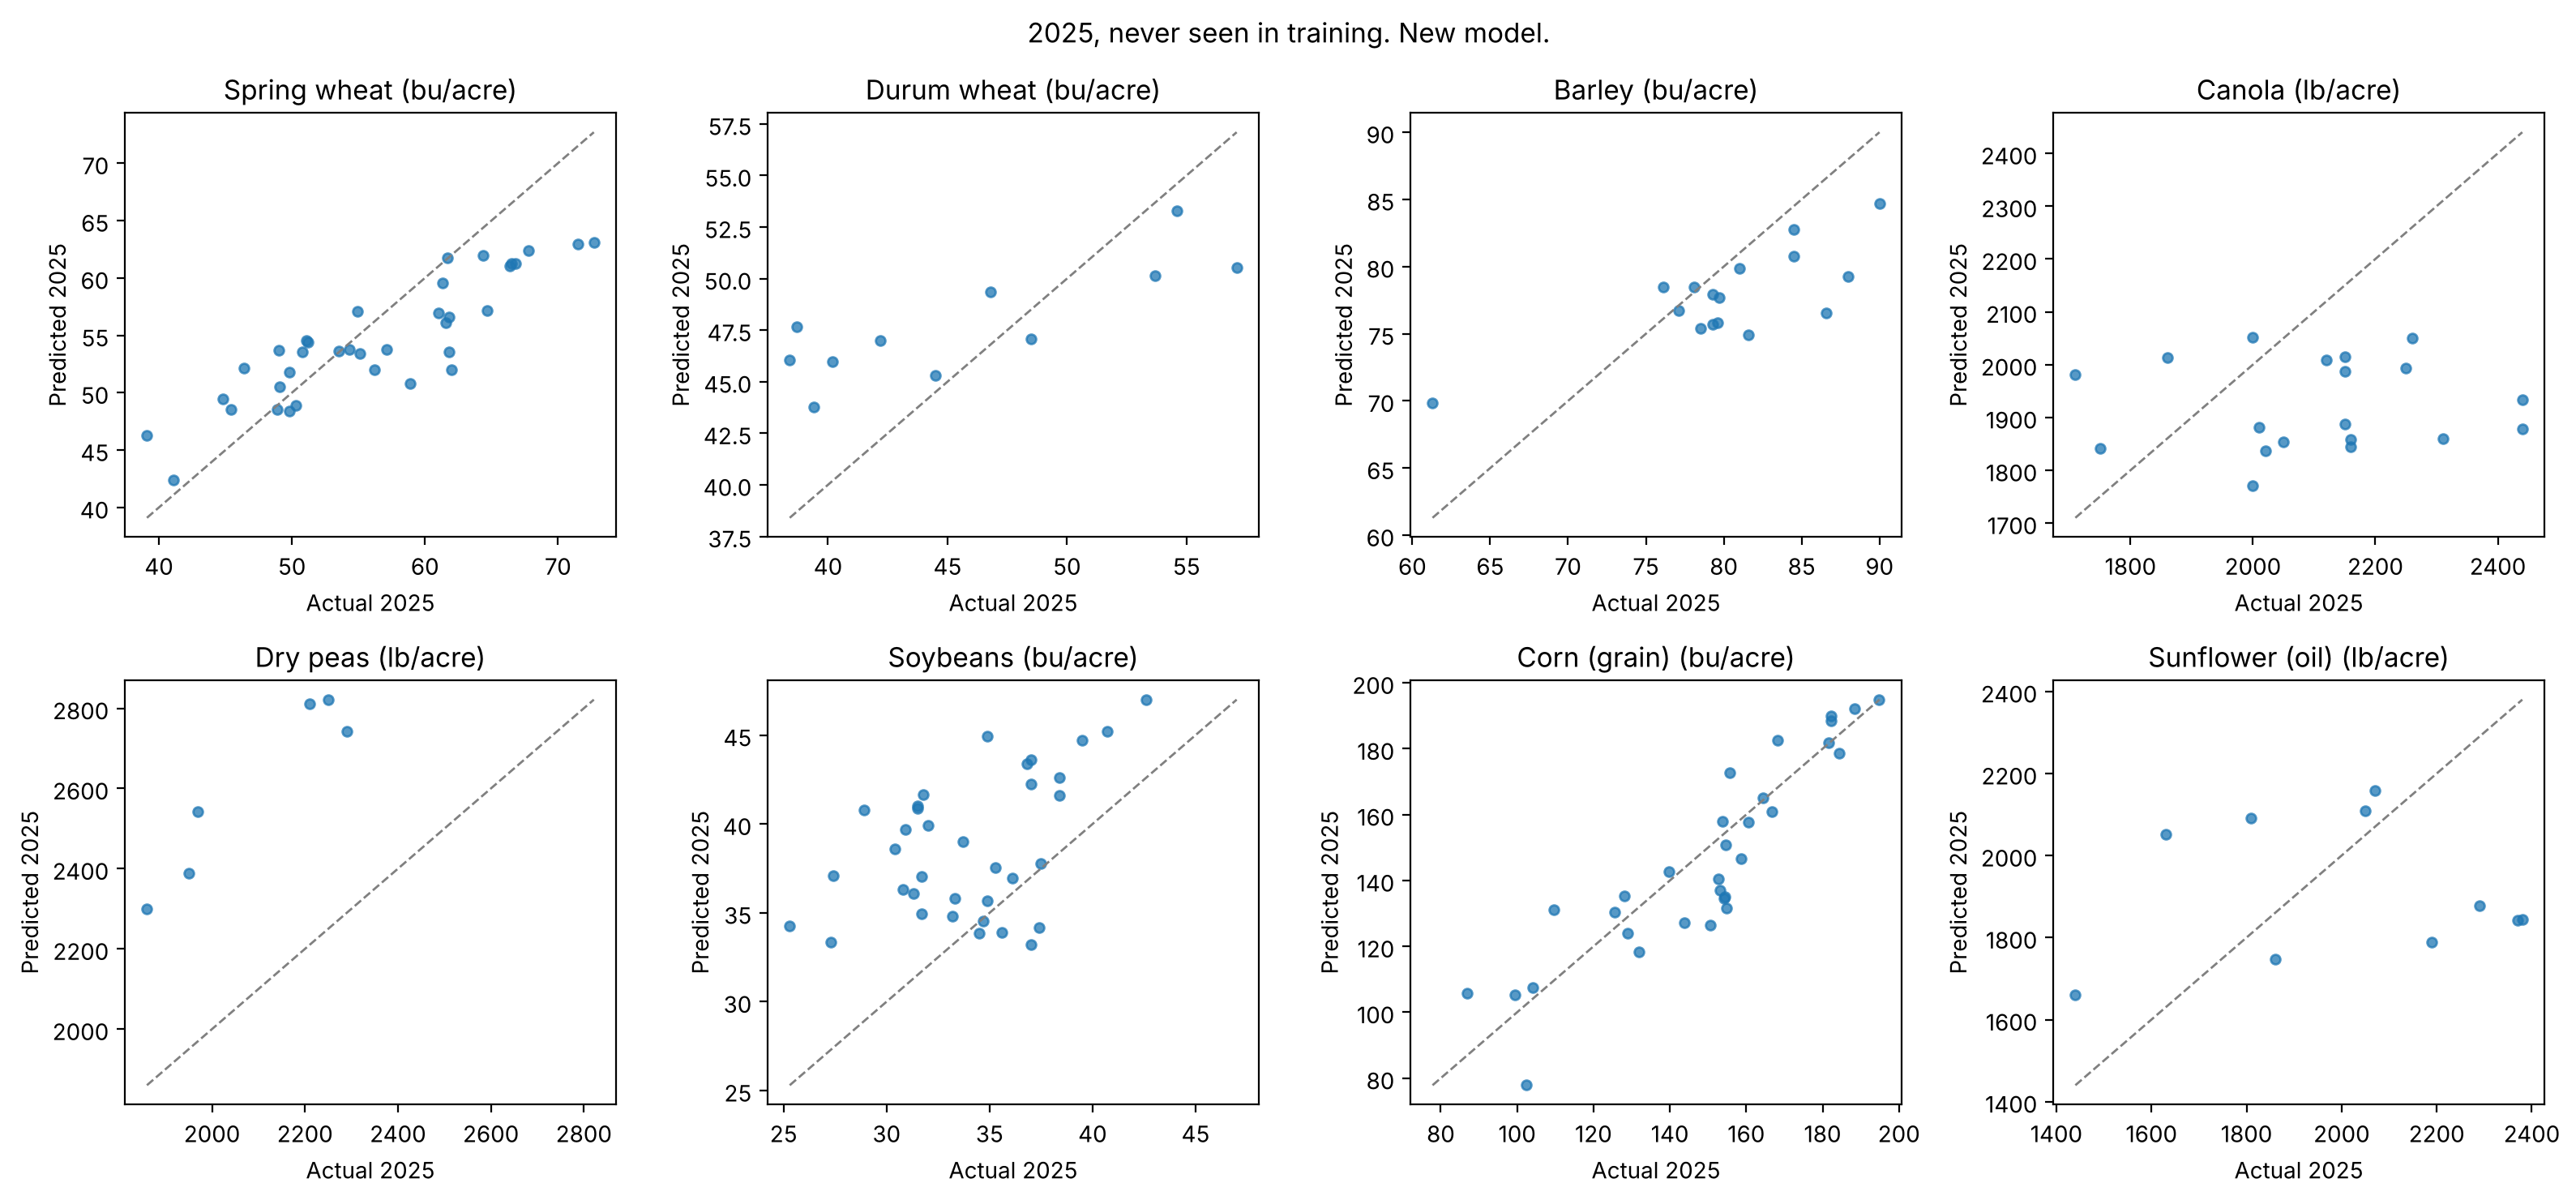

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, crop in zip(axes.ravel(), CROPS):
    part = holdout_predictions[holdout_predictions["crop"] == crop]
    ax.scatter(part["yield"], part["predicted"], s=18, alpha=0.75)
    lo, hi = min(part["yield"].min(), part["predicted"].min()), max(part["yield"].max(), part["predicted"].max())
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="gray", linewidth=1)
    ax.set_title(f"{CROPS[crop]['label']} ({CROPS[crop]['unit']})")
    ax.set_xlabel("Actual 2025"); ax.set_ylabel("Predicted 2025")
fig.suptitle("2025, never seen in training. New model.")
fig.tight_layout()
plt.show()

## 9. From model to "what if": dry, typical, and wet seasons

For every county, the 25 seasons are sorted by May to September rainfall at that county:

* **Dry** = the 6 driest seasons
* **Typical** = the 13 in the middle
* **Wet** = the 6 wettest

The app's numbers are built in two parts, so each part does the job it is good at:

* **Level (the "typical" number):** the county's middle reported yield for 2020 to 2025. That is real data at today's yield level. If a county has fewer than 3 reports in that window, the level is estimated from the model and the statewide pattern, and the app marks it as a rough estimate.
* **Season effect (dry or wet):** the model's percent change from typical. To get the model's answer for year Y, it is trained on every year **except** Y, so it never gets to memorize the answer.

A crop is only shown for a county if USDA reported it there in at least 4 years since 2010. No reports usually means few farms grow it there.

In [16]:
MIN_REPORTED_YEARS = 4
SEASON_N = 6

def scenario_predictions(crop):
    """Model's yield relative to trend, for every county that grows the crop, under each year's weather."""
    d = data[data["crop"] == crop]
    reported = d[d["year"] >= 2010].groupby("county_fips")["year"].nunique()
    grown = reported[reported >= MIN_REPORTED_YEARS].index
    targets = county_weather[county_weather["county_fips"].isin(grown)]
    rows = []
    for year in YEARS:
        forest, _ = fit_new_model(d[d["year"] != year])
        test = targets[targets["year"] == year]
        rows.append(pd.DataFrame({"crop": crop, "county_fips": test["county_fips"].to_numpy(),
                                  "year": year, "relative": forest.predict(test[FEATURES])}))
    return pd.concat(rows, ignore_index=True)

scenario_long = pd.concat([scenario_predictions(crop) for crop in CROPS], ignore_index=True)

# Season group for every county and year, from that county's own rainfall ranking
rain = county_weather[["county_fips", "year", "total_rain_mm"]].copy()
rain["rank"] = rain.groupby("county_fips")["total_rain_mm"].rank(method="first")
rain["season"] = np.select([rain["rank"] <= SEASON_N, rain["rank"] > len(YEARS) - SEASON_N], ["dry", "wet"], default="typical")

scenario_long = scenario_long.merge(rain[["county_fips", "year", "season"]], on=["county_fips", "year"])
scenarios = scenario_long.pivot_table(index=["crop", "county_fips"], columns="season", values="relative", aggfunc="mean").reset_index()
scenarios["dry_change"] = scenarios["dry"] / scenarios["typical"] - 1
scenarios["wet_change"] = scenarios["wet"] / scenarios["typical"] - 1

# Level: middle reported yield, 2020 to 2025, where the county has at least 3 reports
recent = data[data["year"] >= LAST_YEAR - 5]
level = recent.groupby(["crop", "county_fips"])["yield"].agg(recent_median="median", recent_reports="size").reset_index()
scenarios = scenarios.merge(level, on=["crop", "county_fips"], how="left")
has_level = scenarios["recent_reports"].fillna(0) >= 3
# Where reports are thin: the model's typical value for the county, scaled to the level of counties that do report
state_scale = (scenarios[has_level].assign(r=lambda t: t["recent_median"] / t["typical"]).groupby("crop")["r"].median())
scenarios["level_source"] = np.where(has_level, "reports", "estimate")
scenarios["level"] = np.where(has_level, scenarios["recent_median"], scenarios["typical"] * scenarios["crop"].map(state_scale))
scenarios["level_dry"] = scenarios["level"] * (1 + scenarios["dry_change"])
scenarios["level_wet"] = scenarios["level"] * (1 + scenarios["wet_change"])
scenarios.to_csv(PROCESSED / "fieldshift_scenarios.csv", index=False)

print("County-crop pairs:", len(scenarios), "| level from reports:", int(has_level.sum()), "| estimated:", int((~has_level).sum()))
state_view = (scenarios.groupby("crop")[["dry_change", "wet_change"]].mean() * 100).loc[list(CROPS)]
print("\nModel's season effect, average across counties (% change from typical):")
display(state_view.round(1))

County-crop pairs: 304 | level from reports: 228 | estimated: 76

Model's season effect, average across counties (% change from typical):


,dry_change,wet_change
crop,,
spring_wheat,-11.8,5.1
durum,-14.8,7.9
barley,-12.9,5.9
canola,-16.5,4.4
dry_peas,-3.0,4.1
soybeans,-5.7,5.1
corn,-5.5,5.5
sunflower,-1.4,-0.9


### Sanity check on the scenarios

The season effects come from the model. Do real yields show the same pattern? Below: actual reported yields, divided by the trend so old and new years compare fairly, averaged by season group.

In [17]:
check_rows = []
for crop in CROPS:
    d = data[data["crop"] == crop].merge(rain[["county_fips", "year", "season"]], on=["county_fips", "year"])
    trend = fit_trend(d)
    actual = d.assign(relative=d["yield"] / trend(d["year"])).groupby("season")["relative"].mean()
    check_rows.append({"crop": crop,
                       "actual dry vs typical %": (actual["dry"] / actual["typical"] - 1) * 100,
                       "model dry vs typical %": state_view.loc[crop, "dry_change"],
                       "actual wet vs typical %": (actual["wet"] / actual["typical"] - 1) * 100,
                       "model wet vs typical %": state_view.loc[crop, "wet_change"]})
check = pd.DataFrame(check_rows).set_index("crop")
display(check.round(1))

,actual dry vs typical %,model dry vs typical %,actual wet vs typical %,model wet vs typical %
crop,,,,
spring_wheat,-11.0,-11.8,1.3,5.1
durum,-20.8,-14.8,10.0,7.9
barley,-13.0,-12.9,-0.4,5.9
canola,-16.8,-16.5,1.2,4.4
dry_peas,-9.3,-3.0,-2.0,4.1
soybeans,-6.9,-5.7,5.5,5.1
corn,-12.0,-5.5,3.7,5.5
sunflower,-2.2,-1.4,-4.8,-0.9


One caution: "dry" here means the 6 lowest rainfall seasons at that county. A drought that is also very hot, like 2021, hits harder than this average. The app shows each county's worst reported year next to the dry estimate for that reason.

## 10. Write the app's data file

Everything the web page needs goes into `docs/data.js`: crops, prices, test results, county scenarios, reported history, and the county outlines for the map.

In [18]:
geo_file = RAW / "nd_counties.geojson"
if not geo_file.exists():
    url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
    us = requests.get(url, timeout=120).json()
    nd = [f for f in us["features"] if f["properties"]["STATE"] == "38"]
    geo_file.write_text(json.dumps({"type": "FeatureCollection", "features": [
        {"type": "Feature", "id": f["id"], "properties": {"fips": f["id"], "name": f["properties"]["NAME"]},
         "geometry": f["geometry"]} for f in nd]}))
geo = json.loads(geo_file.read_text())

def clean(value, digits=1):
    return None if value is None or pd.isna(value) else round(float(value), digits)

crop_meta = {}
for key, c in CROPS.items():
    h = holdout[holdout["crop"] == key].set_index("model")
    crop_meta[key] = {
        "label": c["label"], "unit": c["unit"], "needs": c["needs"],
        "price": prices[key]["price"], "price_year": prices[key]["year"],
        "price_per": c["unit"].split("/")[0],
        "test_error": clean(summary.loc[key, "New model"]),
        "test_error_pct": clean(summary_pct.loc[key, "New model"]),
        "county_avg_error": clean(summary.loc[key, "County average"]),
        "county_avg_error_pct": clean(summary_pct.loc[key, "County average"]),
        "dry_error_pct": clean(dry_pct.loc[key, "New model"]),
        "county_avg_dry_error_pct": clean(dry_pct.loc[key, "County average"]),
        "test_years": int(folds[folds["crop"] == key]["year"].nunique()),
        "error_2025_pct": clean(h.loc["New model", "pct_of_yield"]),
        "county_avg_error_2025_pct": clean(h.loc["County average", "pct_of_yield"]),
        "counties_2025": int(h.loc["New model", "n"]),
        "check": {"actual_dry": clean(check.loc[key, "actual dry vs typical %"]),
                  "model_dry": clean(check.loc[key, "model dry vs typical %"]),
                  "actual_wet": clean(check.loc[key, "actual wet vs typical %"]),
                  "model_wet": clean(check.loc[key, "model wet vs typical %"])},
    }

county_out = {}
for c in counties.itertuples(index=False):
    r = rain[rain["county_fips"] == c.county_fips].sort_values("year")
    entry = {
        "name": c.name,
        "dry_years": [int(v) for v in r[r["season"] == "dry"]["year"]],
        "wet_years": [int(v) for v in r[r["season"] == "wet"]["year"]],
        "crops": {},
    }
    for key in CROPS:
        s = scenarios[(scenarios["crop"] == key) & (scenarios["county_fips"] == c.county_fips)]
        if s.empty:
            continue
        history = data[(data["crop"] == key) & (data["county_fips"] == c.county_fips)].sort_values("year")
        digits = 1 if CROPS[key]["unit"] == "bu/acre" else 0
        entry["crops"][key] = {
            "dry": clean(s["level_dry"].iloc[0], digits), "typical": clean(s["level"].iloc[0], digits),
            "wet": clean(s["level_wet"].iloc[0], digits),
            "level_source": s["level_source"].iloc[0],
            "history": [[int(yr), clean(val, digits)] for yr, val in zip(history["year"], history["yield"])],
        }
    county_out[c.county_fips] = entry

app_data = {
    "meta": {
        "generated": date.today().isoformat(),
        "years": [FIRST_YEAR, LAST_YEAR],
        "season_n": SEASON_N,
        "sources": ["NASA POWER daily weather and soil wetness (MERRA-2, CERES) and satellite rain (GPM IMERG)",
                    "USDA NASS Quick Stats county yields and state prices", "US Census Bureau county gazetteer"],
    },
    "crops": crop_meta,
    "counties": county_out,
    "geo": geo,
}

(DOCS / "data.js").write_text("window.FIELDSHIFT = " + json.dumps(app_data, separators=(",", ":")) + ";\n")
print("Wrote docs/data.js:", round((DOCS / "data.js").stat().st_size / 1024), "KB")
print("Counties with at least one crop:", sum(1 for v in county_out.values() if v["crops"]), "of", len(county_out))
print("County-crop pairs:", sum(len(v["crops"]) for v in county_out.values()))

Wrote docs/data.js: 128 KB
Counties with at least one crop: 53 of 53
County-crop pairs: 304
